In [1]:
import os
import json
from pathlib import Path
import xarray as xr
import leafmap
from pyproj import Transformer
import matplotlib.pyplot as plt
import numpy as np

path = '../data/GEODATACUBE_ZARR_openEO'

# Files

Files provided by ICGC

In [2]:
os.listdir(path)

['Geodatacube_nDSM2025.zarr',
 'Geodatacube_orto2024.zarr',
 'Field_ROI_geodatacube.gpkg',
 'AOI.geojson',
 'AOI.gpkg',
 'Geodatacube_S22024_2025.json',
 'Geodatacube_nDSM2024.zarr',
 'GeoDataCube_access_XARRAYvsZARR_cat.ipynb',
 'GeoDataCube_access_XARRAYvsZARR_cat.html',
 'GeoDataCube_cobertes-sol-v1r0-2023.zarr',
 'Geodatacube_orto2025.zarr',
 'Geodatacube_S22024_2025.zarr',
 'Field2_ROI_geodatacube.gpkg',
 '.ipynb_checkpoints',
 'ReadMe.txt']

In [3]:
zarr_dict = {
    "orto": {
        "2024": os.path.join(path, "Geodatacube_orto2024.zarr"),
        "2025": os.path.join(path, "Geodatacube_orto2025.zarr"),
    },
    "ndsm": {
        "2024": os.path.join(path, "Geodatacube_nDSM2024.zarr"),
        "2025": os.path.join(path, "Geodatacube_nDSM2025.zarr"),
    },
    "sentinel4D": os.path.join(path, "Geodatacube_S22024_2025.zarr"),
    "label": os.path.join(path, "GeoDataCube_cobertes-sol-v1r0-2023.zarr"),
}
zarr_dict

{'orto': {'2024': '../data/GEODATACUBE_ZARR_openEO/Geodatacube_orto2024.zarr',
  '2025': '../data/GEODATACUBE_ZARR_openEO/Geodatacube_orto2025.zarr'},
 'ndsm': {'2024': '../data/GEODATACUBE_ZARR_openEO/Geodatacube_nDSM2024.zarr',
  '2025': '../data/GEODATACUBE_ZARR_openEO/Geodatacube_nDSM2025.zarr'},
 'sentinel4D': '../data/GEODATACUBE_ZARR_openEO/Geodatacube_S22024_2025.zarr',
 'label': '../data/GEODATACUBE_ZARR_openEO/GeoDataCube_cobertes-sol-v1r0-2023.zarr'}

# Orto

In [7]:
ds_orto = xr.open_zarr(zarr_dict['orto']['2024'])
ds_orto

<xarray.Dataset> Size: 40GB
Dimensions:      (bands: 4, y: 78400, x: 128000)
Coordinates:
  * bands        (bands) StringDType() 64B 'BLU' 'GRN' 'RED' 'NIR'
  * y            (y) float64 627kB 4.631e+06 4.631e+06 ... 4.611e+06 4.611e+06
  * x            (x) float64 1MB 4.27e+05 4.27e+05 ... 4.59e+05 4.59e+05
    spatial_ref  int64 8B ...
Data variables:
    data         (bands, y, x) uint8 40GB ...
Attributes:
    width:        128000
    height:       78400
    count:        4
    dtype:        uint8
    bounds:       [427000.0, 4611300.0, 459000.0, 4630900.0]
    transform:    [0.25, 0.0, 427000.0, 0.0, -0.25, 4630900.0, 0.0, 0.0, 1.0]
    crs:          PROJCS["ETRS89 / UTM zone 31N",GEOGCS["ETRS89",DATUM["Europ...
    Conventions:  CF-1.8

Zarr root metadata stores the footprint in **EPSG:25831** (`bounds`: west, south, east, north in metres). Below we reproject to WGS84 lon/lat and draw it on a basemap (optional overlay: `AOI.geojson`).

In [8]:
zarr_store = Path(zarr_dict["orto"]["2024"])  # same spatial extent as other demo layers
zarr_name = zarr_store.name

meta = json.loads((zarr_store / "zarr.json").read_text())
minx, miny, maxx, maxy = meta["attributes"]["bounds"]

to_wgs84 = Transformer.from_crs("EPSG:25831", "EPSG:4326", always_xy=True)
west, south = to_wgs84.transform(minx, miny)
east, north = to_wgs84.transform(maxx, maxy)
bbox_lonlat = [west, south, east, north]

print(
    f"{zarr_name} in WGS84 (west, south, east, north): "
    f"{west:.6f}, {south:.6f}, {east:.6f}, {north:.6f}"
)

m = leafmap.Map(height="500px")
m.add_bbox(
    bbox_lonlat,
    layer_name=f"{zarr_name} extent",
    color="#e41a1c",
    fill_color="#e41a1c",
    fill_opacity=0.15,
)

m.zoom_to_bounds(bbox_lonlat)
m.add_layer_control()
m

Geodatacube_orto2024.zarr in WGS84 (west, south, east, north): 2.123335, 41.650104, 2.506257, 41.828924


Map(center=[20, 0], controls=(ZoomControl(options=['position', 'zoom_in_text', 'zoom_in_title', 'zoom_out_text…

In [6]:
west, south, east, north = m.user_roi_bounds()
assert west is not None, "Draw a rectangle on the map first"

to_utm = Transformer.from_crs("EPSG:4326", "EPSG:25831", always_xy=True)
xmin, ymin = to_utm.transform(west, south)
xmax, ymax = to_utm.transform(east, north)

bbox_dict = {"xmin": xmin, "xmax": xmax, "ymin": ymin, "ymax": ymax}
bbox_dict

TypeError: cannot unpack non-iterable NoneType object

In [ ]:
ds_orto_sub = ds_orto['data'].sel(
    x=slice(bbox_dict['xmin'], bbox_dict['xmax']), 
    y=slice(bbox_dict['ymax'], bbox_dict['ymin'])
)   

ds_orto_sub

<xarray.DataArray 'data' (bands: 4, y: 2016, x: 2976)> Size: 24MB
[23998464 values with dtype=uint8]
Coordinates:
  * bands        (bands) StringDType() 64B 'BLU' 'GRN' 'RED' 'NIR'
  * y            (y) float64 16kB 4.628e+06 4.628e+06 ... 4.628e+06 4.628e+06
  * x            (x) float64 24kB 4.348e+05 4.348e+05 ... 4.356e+05 4.356e+05
    spatial_ref  int64 8B 0
Attributes:
    grid_mapping:  spatial_ref

> BANDS ARE NOT IN THE CORRECT ORDER !!!

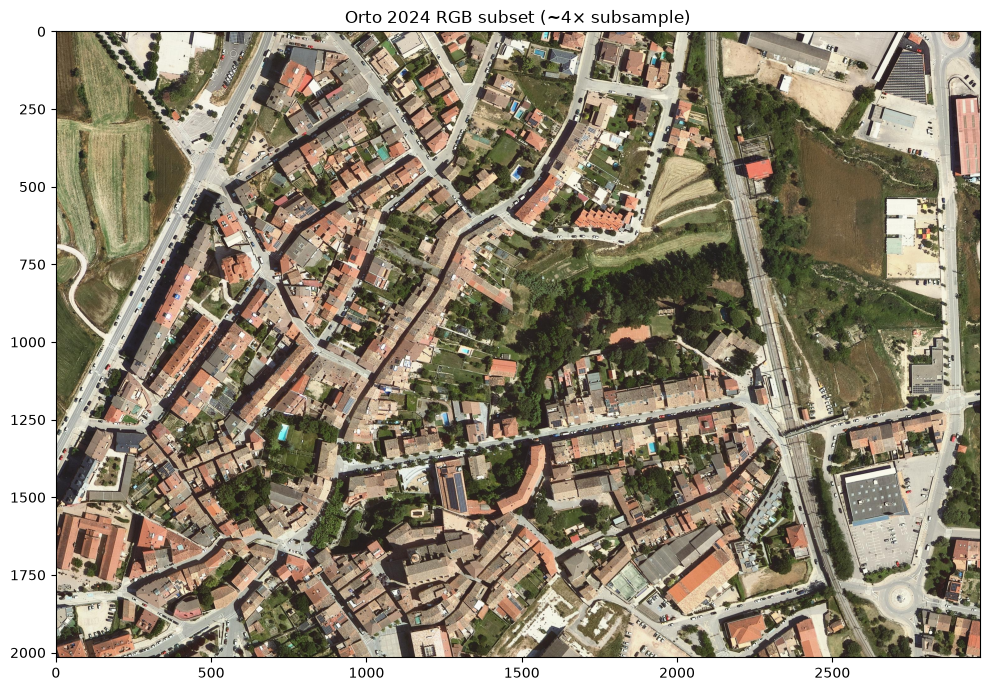

In [ ]:
step = 4 # take every 4th pixel (subsampling stride)
rgb_da = (
    # ds_orto_sub.sel(bands=["RED", "GRN", "BLU"]) # wrong order
    ds_orto_sub.sel(bands=["BLU", "GRN", "RED"])
    # .isel(x=slice(None, None, step), y=slice(None, None, step))
    .load()
    .transpose("y", "x", "bands")
)
rgb = rgb_da.values  

plt.figure(figsize=(10, 10))
plt.imshow(rgb, origin="upper")
plt.title(f"Orto 2024 RGB subset (~{step}× subsample)")
plt.tight_layout()
plt.show()